# FireWatch Indonesia - Spatial Analysis
## Analisis Spasial Hotspot per Provinsi

**Tujuan:**
- Menggabungkan data hotspot dengan batas wilayah administratif
- Menganalisis distribusi hotspot per provinsi
- Membuat visualisasi peta choropleth
- Mengidentifikasi provinsi dengan risiko tertinggi

## 1. Import Library

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 2. Load Data

In [2]:
# Load hotspot data
df = pd.read_csv('../data/raw/fire_nrt_SV-C2_800747.csv')
df['acq_date'] = pd.to_datetime(df['acq_date'])
print(f"Hotspot data: {len(df):,} rows")

# Load province boundaries
provinsi_gdf = gpd.read_file('../data/raw/indonesia-province-simple.json')
print(f"Province data: {len(provinsi_gdf)} provinces")

df.head()

Hotspot data: 192,897 rows
Province data: 32 provinces


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-7.82814,139.04887,338.59,0.43,0.46,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.55,9.25,D
1,-8.06223,140.56680,348.05,0.52,0.42,2026-08-01,402,SNPP,SNPP,n,2.0NRT,298.69,18.24,D
2,-8.06363,140.55728,332.29,0.52,0.42,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.66,4.26,D
3,-8.07347,140.49045,328.67,0.53,0.42,2026-08-01,402,SNPP,SNPP,l,2.0NRT,299.51,6.33,D
4,-8.05176,140.58467,329.44,0.52,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.81,5.05,D


## 3. Convert Hotspot to GeoDataFrame

In [3]:
# Create Point geometry from coordinates
geometry = [Point(xy) for xy in zip(df['longitude'], df['latitude'])]
hotspot_gdf = gpd.GeoDataFrame(df, geometry=geometry, crs='EPSG:4326')

# Ensure same CRS
if provinsi_gdf.crs != hotspot_gdf.crs:
    provinsi_gdf = provinsi_gdf.to_crs(hotspot_gdf.crs)

print(f"GeoDataFrame created with {len(hotspot_gdf):,} points")
hotspot_gdf.head()

GeoDataFrame created with 192,897 points


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,geometry
0,-7.82814,139.04887,338.59,0.43,0.46,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.55,9.25,D,POINT (139.04887 -7.82814)
1,-8.06223,140.56680,348.05,0.52,0.42,2026-08-01,402,SNPP,SNPP,n,2.0NRT,298.69,18.24,D,POINT (140.5668 -8.06223)
2,-8.06363,140.55728,332.29,0.52,0.42,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.66,4.26,D,POINT (140.55728 -8.06363)
3,-8.07347,140.49045,328.67,0.53,0.42,2026-08-01,402,SNPP,SNPP,l,2.0NRT,299.51,6.33,D,POINT (140.49045 -8.07347)
4,-8.05176,140.58467,329.44,0.52,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.81,5.05,D,POINT (140.58467 -8.05176)


## 4. Spatial Join

Menggabungkan hotspot dengan provinsi berdasarkan lokasi geografis

In [4]:
print("Performing spatial join (this may take a few minutes)...")
hotspot_with_province = gpd.sjoin(hotspot_gdf, provinsi_gdf, how='left', predicate='within')
print("Spatial join completed!")

hotspot_with_province.head()

Performing spatial join (this may take a few minutes)...
Spatial join completed!


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,geometry,index_right,ID,kode,Propinsi,SUMBER
0,-7.82814,139.04887,338.59,0.43,0.46,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.55,9.25,D,POINT (139.04887 -7.82814),0.0,1.0,85.0,IRIAN JAYA TIMUR,Peta Dasar BAKOSURTANAL Skala 1 : 250.000
1,-8.06223,140.56680,348.05,0.52,0.42,2026-08-01,402,SNPP,SNPP,n,2.0NRT,298.69,18.24,D,POINT (140.5668 -8.06223),0.0,1.0,85.0,IRIAN JAYA TIMUR,Peta Dasar BAKOSURTANAL Skala 1 : 250.000
2,-8.06363,140.55728,332.29,0.52,0.42,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.66,4.26,D,POINT (140.55728 -8.06363),0.0,1.0,85.0,IRIAN JAYA TIMUR,Peta Dasar BAKOSURTANAL Skala 1 : 250.000
3,-8.07347,140.49045,328.67,0.53,0.42,2026-08-01,402,SNPP,SNPP,l,2.0NRT,299.51,6.33,D,POINT (140.49045 -8.07347),0.0,1.0,85.0,IRIAN JAYA TIMUR,Peta Dasar BAKOSURTANAL Skala 1 : 250.000
4,-8.05176,140.58467,329.44,0.52,0.41,2026-08-01,402,SNPP,SNPP,n,2.0NRT,296.81,5.05,D,POINT (140.58467 -8.05176),0.0,1.0,85.0,IRIAN JAYA TIMUR,Peta Dasar BAKOSURTANAL Skala 1 : 250.000


## 5. Detect Province Column Name

In [5]:
# Find province name column
nama_kolom = None
for col in ['Propinsi', 'province', 'name', 'NAME_1', 'PROVINSI', 'Nama']:
    if col in hotspot_with_province.columns:
        nama_kolom = col
        break

if nama_kolom is None:
    print("Available columns:", hotspot_with_province.columns.tolist())
    raise ValueError("Province column not found")

print(f"Province column: '{nama_kolom}'")

Province column: 'Propinsi'


## 6. Analisis per Provinsi

In [6]:
# Count hotspots per province
hotspot_per_provinsi = hotspot_with_province.groupby(nama_kolom).size().reset_index(name='jumlah_hotspot')
hotspot_per_provinsi = hotspot_per_provinsi.sort_values('jumlah_hotspot', ascending=False)

# Calculate percentage
total_hotspot = hotspot_per_provinsi['jumlah_hotspot'].sum()
hotspot_per_provinsi['persentase'] = (hotspot_per_provinsi['jumlah_hotspot'] / total_hotspot * 100)

print(f"Total hotspot identified: {total_hotspot:,}")
print(f"\nTop 10 Provinces:")
hotspot_per_provinsi.head(10)

Total hotspot identified: 191,697

Top 10 Provinces:


,Propinsi,jumlah_hotspot,persentase
14,KALIMANTAN BARAT,49645,25.897641
16,KALIMANTAN TENGAH,47458,24.756778
9,IRIAN JAYA TIMUR,18259,9.524927
17,KALIMANTAN TIMUR,13342,6.959942
30,SUMATERA SELATAN,11977,6.247881
15,KALIMANTAN SELATAN,9730,5.075718
19,MALUKU,4628,2.414227
21,NUSA TENGGARA TIMUR,4290,2.237907
25,SULAWESI SELATAN,3069,1.600964
13,JAWA TIMUR,3043,1.587401


## 7. Visualisasi: Bar Chart Top 10 Provinsi

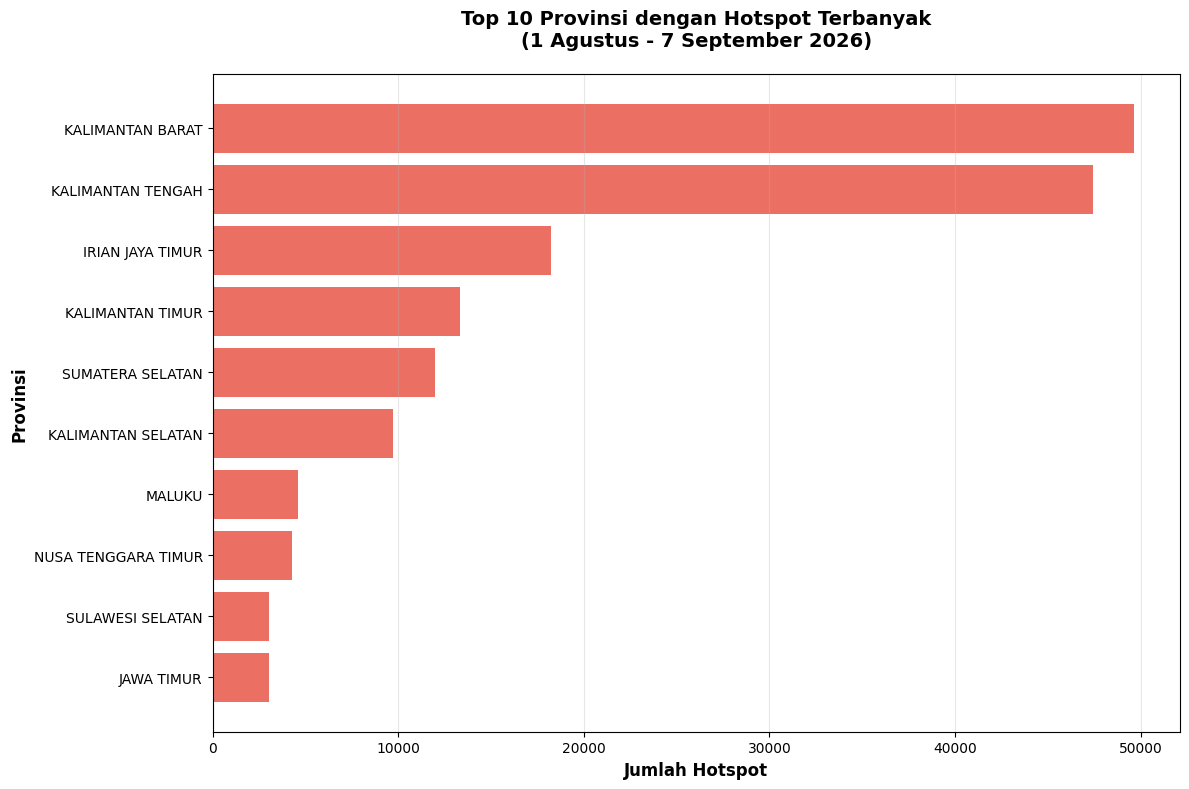

In [7]:
plt.figure(figsize=(12, 8))
top10 = hotspot_per_provinsi.head(10)
plt.barh(range(len(top10)), top10['jumlah_hotspot'], color='#e74c3c', alpha=0.8)
plt.yticks(range(len(top10)), top10[nama_kolom])
plt.xlabel('Jumlah Hotspot', fontsize=12, fontweight='bold')
plt.ylabel('Provinsi', fontsize=12, fontweight='bold')
plt.title('Top 10 Provinsi dengan Hotspot Terbanyak\n(1 Agustus - 7 September 2026)', 
          fontsize=14, fontweight='bold', pad=20)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../images/09_top_provinsi.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Peta Choropleth

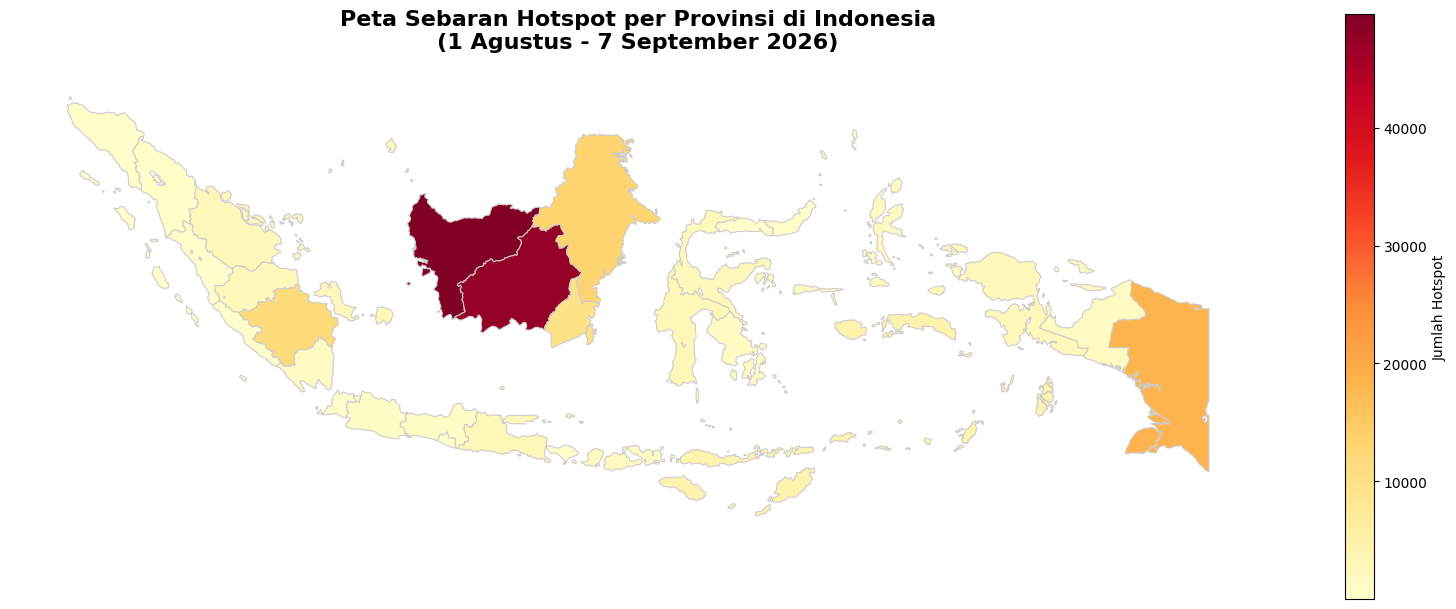

In [8]:
# Merge province boundaries with hotspot counts
provinsi_with_hotspot = provinsi_gdf.merge(
    hotspot_per_provinsi, 
    left_on=nama_kolom, 
    right_on=nama_kolom, 
    how='left'
)
provinsi_with_hotspot['jumlah_hotspot'] = provinsi_with_hotspot['jumlah_hotspot'].fillna(0)

# Plot choropleth
fig, ax = plt.subplots(1, 1, figsize=(16, 12))
provinsi_with_hotspot.plot(
    column='jumlah_hotspot',
    cmap='YlOrRd',
    linewidth=0.8,
    ax=ax,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': 'Jumlah Hotspot', 'shrink': 0.5}
)
ax.set_title('Peta Sebaran Hotspot per Provinsi di Indonesia\n(1 Agustus - 7 September 2026)', 
             fontsize=16, fontweight='bold', pad=20)
ax.axis('off')
plt.tight_layout()
plt.savefig('../images/10_peta_choropleth.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Peta dengan Overlay Hotspot

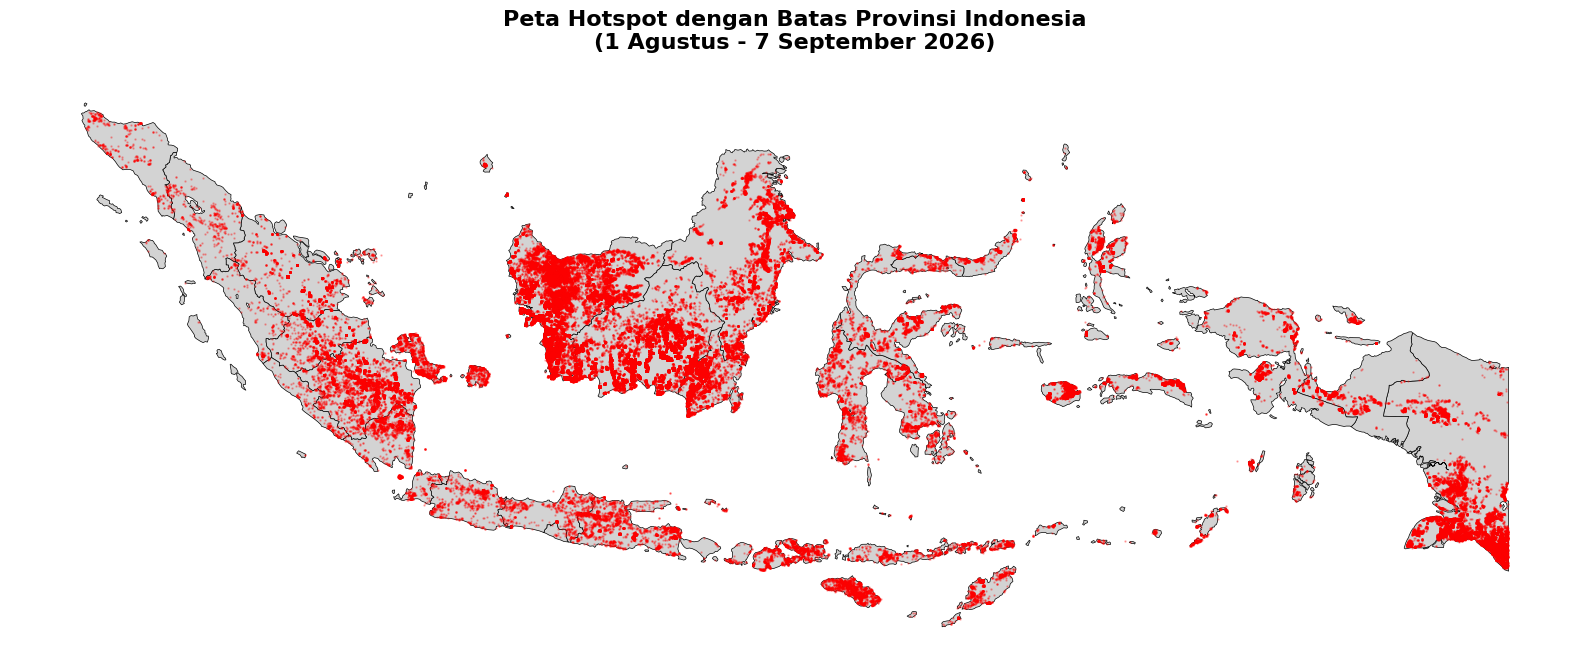

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(16, 12))
provinsi_gdf.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5)
hotspot_gdf.plot(ax=ax, color='red', markersize=0.5, alpha=0.3)
ax.set_title('Peta Hotspot dengan Batas Provinsi Indonesia\n(1 Agustus - 7 September 2026)', 
             fontsize=16, fontweight='bold', pad=20)
ax.axis('off')
plt.tight_layout()
plt.savefig('../images/11_peta_overlay.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Save Results

In [10]:
# Save to CSV
hotspot_per_provinsi.to_csv('../data/processed/hotspot_per_provinsi.csv', index=False)
print("Results saved to: data/processed/hotspot_per_provinsi.csv")

# Display summary statistics
print("\nSummary Statistics:")
print(f"Mean hotspot per province: {hotspot_per_provinsi['jumlah_hotspot'].mean():.0f}")
print(f"Median hotspot per province: {hotspot_per_provinsi['jumlah_hotspot'].median():.0f}")
print(f"Std Dev: {hotspot_per_provinsi['jumlah_hotspot'].std():.0f}")

Results saved to: data/processed/hotspot_per_provinsi.csv

Summary Statistics:
Mean hotspot per province: 5991
Median hotspot per province: 1849
Std Dev: 11951
